**Unit 2 Q1: Particle in a finite potential well**

Numerical: finite difference. Analytical: roots of the transcendental equations.

State    Numerical (eV)    Analytical (eV)
0       -6.7226          -6.7202
1       -3.1794          -3.1714


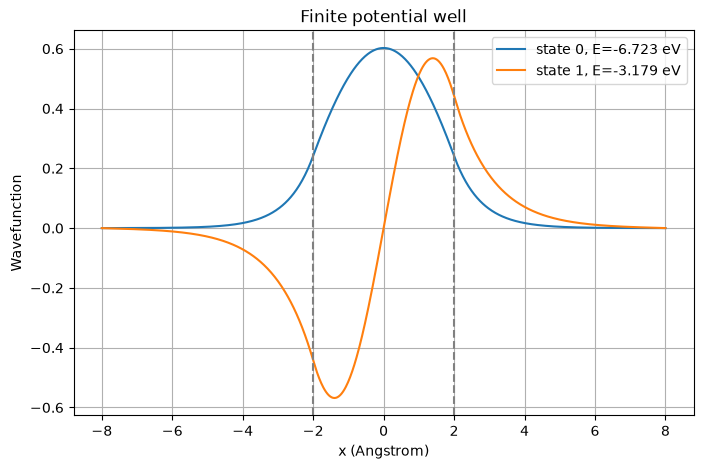

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

hc = 1973.0
mc2 = 0.511e6
c = hc ** 2 / (2 * mc2)

a = 2.0
V0 = 8.0

N = 800
x = np.linspace(-8, 8, N)
dx = x[1] - x[0]
V = np.where(abs(x) < a, -V0, 0.0)

H = np.diag(2 * c / dx ** 2 + V)
H = H + np.diag(-c / dx ** 2 * np.ones(N - 1), 1)
H = H + np.diag(-c / dx ** 2 * np.ones(N - 1), -1)

E, psi = np.linalg.eigh(H)
bound = E < 0
E_numerical = E[bound]
psi = psi[:, bound]

z0 = a * np.sqrt(V0 / c)


def even(z):
    return z * np.sin(z) - np.sqrt(z0 ** 2 - z ** 2) * np.cos(z)


def odd(z):
    return z * np.cos(z) + np.sqrt(z0 ** 2 - z ** 2) * np.sin(z)


z = np.linspace(0.001, z0 - 1e-6, 2000)
E_analytical = []
for f in (even, odd):
    for i in range(len(z) - 1):
        if f(z[i]) * f(z[i + 1]) < 0:
            root = brentq(f, z[i], z[i + 1])
            E_analytical.append(-V0 + c * (root / a) ** 2)
E_analytical = np.sort(E_analytical)

print("State    Numerical (eV)    Analytical (eV)")
for i in range(len(E_analytical)):
    print(i, "     ", round(E_numerical[i], 4), "        ", round(E_analytical[i], 4))

plt.figure(figsize=(8, 5))
for i in range(len(E_numerical)):
    u = psi[:, i] / np.sqrt(np.sum(psi[:, i] ** 2) * dx)
    plt.plot(x, u, label=f"state {i}, E={E_numerical[i]:.3f} eV")

plt.axvline(-a, color="gray", linestyle="--")
plt.axvline(a, color="gray", linestyle="--")
plt.xlabel("x (Angstrom)")
plt.ylabel("Wavefunction")
plt.title("Finite potential well")
plt.legend()
plt.grid(True)
plt.show()
